# Predicting a Vehicle's Fuel Technology from Its Specifications

**Question:** given only a vehicle's engine size, cylinders, drive type, transmission, make, class, and model year, can a model tell whether it is a gasoline car, a hybrid, a plug-in hybrid, an EV, a diesel, or a flex-fuel vehicle?

This notebook works through the whole supervised-learning workflow on the EPA/DOE Fuel Economy dataset (about 50,000 U.S. vehicle configurations, model years 1984 to 2027): building the label from a raw column, cleaning, encoding, avoiding leakage, selecting features, comparing models against a baseline, tuning, and reading the errors class by class.

### Headline results

| Measure | Result |
|---|---|
| Majority-class baseline (always guess Gasoline) | 0.8652 accuracy |
| Recommended model: tuned k-nearest neighbors | 0.9243 accuracy, 0.6143 macro F1 |
| Logistic regression / random forest (class-weighted) | 0.5055 / 0.7657 accuracy |
| Recall by class (tuned KNN) | EV 1.00, Gasoline 0.98, Diesel 0.52, Hybrid 0.47, Flex fuel 0.31, Plug-in 0.07 |

**Takeaway:** accuracy looks good only because 86.5% of the vehicles are gasoline. The model separates EVs and gasoline vehicles well but misses most hybrids, flex-fuel, diesel, and plug-in vehicles, so macro F1 and per-class recall are the numbers that matter.

## 1. Objective and data

### The objective

I'm using the [EPA/DOE Fuel Economy dataset](https://www.fueleconomy.gov/feg/download.shtml) (`vehicles.csv`, public domain), which has 50,407 vehicles from model years 1984-2027 and 84 columns. I'm modeling a vehicle's fuel technology type from its specifications, such as engine size, cylinders, drive type, transmission, vehicle class, make, and year.

The label comes from the `atvType` column by this rule:

* Blank values become Gasoline
* Hybrid stays Hybrid
* EV stays EV
* Plug-in Hybrid becomes Plug-in
* FFV becomes Flex fuel
* Diesel stays Diesel
* CNG, Bifuel (CNG), Bifuel (LPG), FCV, and eFCV are dropped (122 rows combined)

That leaves six classes and 50,285 labeled rows: Gasoline 43,547, Hybrid 1,899, EV 1,608, Flex fuel 1,538, Diesel 1,246, and Plug-in 447. After the cleaning in Section 4, 48,879 rows remain: Gasoline 42,289 (86.5%), Hybrid 1,891, EV 1,575, Flex fuel 1,538, Diesel 1,145, and Plug-in 441.

I chose this dataset because the EPA catalog lists every vehicle configuration certified for sale in the U.S., so it covers all six fuel types with the same specification columns, and the labels come from the EPA's own `atvType` field rather than from my judgment.

### Source and terms

The data is published by the U.S. Environmental Protection Agency (EPA) and the U.S. Department of Energy (DOE) through [fueleconomy.gov](https://www.fueleconomy.gov/feg/download.shtml). The [Data.gov catalog entry](https://catalog.data.gov/dataset/www-fueleconomy-gov) lists the [EPA Data License](https://edg.epa.gov/EPA_Data_License.htm), under which this and all other EPA-published data are in the public domain, with no restrictions on permitted use. No login, API key, or click-through agreement is needed to download it, and it contains no third-party copyrighted work. That means the dataset and anything built from it, including trained models, can be used, modified, and redistributed freely, including commercially.

### Who is not in this data

Each row is one vehicle configuration (make, model, year, engine, transmission) certified for sale in the U.S. and tested by the EPA from 1984 to 2027. It is not a sample of cars on the road or cars sold, and the values are laboratory test results, not real-world driving.

Under-represented or missing:

* Vehicles sold outside the U.S.
* Heavy vehicles
* Rare technologies, such as CNG, bifuel, and hydrogen fuel cell vehicles (122 rows combined)

The model reflects how the EPA catalog is structured, not what's on the road. Because year, brand, and body style are tangled up with the classes, a vehicle from a brand with little history in the data could be misclassified. The model should not be used for vehicles sold outside the U.S., heavy-duty vehicles, or the fuel types it never saw. It is suited for exploring patterns in the EPA catalog, not for decisions like emissions compliance.

## 2. Setup

Library versions are printed so the results can be reproduced, followed by a few small helpers used throughout: one prints a dataset summary, one reports train and test accuracy beside the majority-class baseline, one runs stratified k-fold cross-validation, and one prints a labeled confusion table.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scikit-learn", sklearn.__version__)

numpy        2.4.6
pandas       2.2.3
scikit-learn 1.6.1


In [2]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import confusion_matrix


def describe_frame(df, label):
    """Shape, columns, and rows per class."""
    print(f"rows: {df.shape[0]}   columns: {df.shape[1]}")
    print("columns:", list(df.columns))
    print(f"rows per class ({label}):")
    print(df[label].value_counts().to_string())


def report(name, model, X_tr, y_tr, X_te, y_te):
    """One model, both scores, and the baseline they have to beat."""
    train_acc = model.score(X_tr, y_tr)
    test_acc = model.score(X_te, y_te)
    base = np.bincount(y_te).max() / len(y_te)
    print(f"=== {name} ===")
    print(f"train accuracy:          {train_acc:.4f}")
    print(f"test accuracy:           {test_acc:.4f}")
    print(f"majority-class baseline: {base:.4f}")
    print(f"test minus baseline:     {test_acc - base:+.4f}")
    print(f"train minus test (gap):  {train_acc - test_acc:+.4f}")
    return train_acc, test_acc


def cv_report(name, model, X, y, k=5):
    """k-fold accuracy as a mean and a spread, beside the baseline."""
    folds = StratifiedKFold(n_splits=k, shuffle=True, random_state=1)
    scores = cross_val_score(model, X, y, cv=folds, scoring="accuracy")
    base = np.bincount(y).max() / len(y)
    print(f"=== {name}: {k}-fold cross-validation ===")
    print(f"fold accuracies:         {np.round(scores, 4)}")
    print(f"mean accuracy:           {scores.mean():.4f}")
    print(f"standard deviation:      {scores.std():.4f}")
    print(f"majority-class baseline: {base:.4f}")
    return scores.mean(), scores.std()


def confusion_table(y_true, y_pred, class_names):
    """The confusion matrix as a labeled table: rows are the truth, columns the prediction."""
    m = confusion_matrix(y_true, y_pred)
    table = pd.DataFrame(m, index=[f"true {c}" for c in class_names],
                         columns=[f"pred {c}" for c in class_names])
    print(table.to_string())
    return table


def describe_figure(text):
    """Print a text description of the figure directly above, for readers who can't see it."""
    print("Figure description:", text)

## 3. Data collection

The CSV is read straight from fueleconomy.gov (no login required), then the class label is built from `atvType` using the rule above.

In [3]:
# Source: https://www.fueleconomy.gov/feg/epadata/vehicles.csv.zip (retrieved Sep 23, 2026)
url = "https://www.fueleconomy.gov/feg/epadata/vehicles.csv.zip"
df = pd.read_csv(url, low_memory=False)

# Build the class label from atvType
label_map = {"Gasoline": "Gasoline", "Diesel": "Diesel", "EV": "EV", "FFV": "Flex fuel",
             "Hybrid": "Hybrid", "Plug-in Hybrid": "Plug-in"}
df["atvType"] = df["atvType"].fillna("Gasoline").str.strip()
df["atvType"] = df["atvType"].map(label_map)   # rare fuel types map to NaN and are dropped later

In [4]:
describe_frame(df, "atvType")

rows: 50647   columns: 84
columns: ['barrels08', 'barrelsA08', 'charge120', 'charge240', 'city08', 'city08U', 'cityA08', 'cityA08U', 'cityCD', 'cityE', 'cityUF', 'co2', 'co2A', 'co2TailpipeAGpm', 'co2TailpipeGpm', 'comb08', 'comb08U', 'combA08', 'combA08U', 'combE', 'combinedCD', 'combinedUF', 'cylinders', 'displ', 'drive', 'engId', 'eng_dscr', 'feScore', 'fuelCost08', 'fuelCostA08', 'fuelType', 'fuelType1', 'ghgScore', 'ghgScoreA', 'highway08', 'highway08U', 'highwayA08', 'highwayA08U', 'highwayCD', 'highwayE', 'highwayUF', 'hlv', 'hpv', 'id', 'lv2', 'lv4', 'make', 'model', 'mpgData', 'phevBlended', 'pv2', 'pv4', 'range', 'rangeCity', 'rangeCityA', 'rangeHwy', 'rangeHwyA', 'trany', 'UCity', 'UCityA', 'UHighway', 'UHighwayA', 'VClass', 'year', 'youSaveSpend', 'baseModel', 'guzzler', 'trans_dscr', 'tCharger', 'sCharger', 'atvType', 'fuelType2', 'rangeA', 'evMotor', 'mfrCode', 'c240Dscr', 'charge240b', 'c240bDscr', 'createdOn', 'modifiedOn', 'startStop', 'phevCity', 'phevHwy', 'phevComb'

## 4. Preprocessing and feature selection

### 4.1 Missing values

Eighteen columns had missing values; the counts are printed below. I treated them in four groups:

* **Blank means "none":** `tCharger` (38,620 blank), `sCharger` (49,240 blank), and `guzzler` (47,548 blank) are blank when the vehicle does not have the feature, so I turned each into a 0/1 flag. `sCharger` is 1 only where the value is "S".
* **Blank is its own category:** `startStop` (31,689 blank) became "unknown", because a blank does not tell me the car lacks the system. `eng_dscr` (18,436 blank) and `trans_dscr` (35,363 blank) became "none".
* **Blank because it does not apply:** EVs have no engine, so `displ` and `cylinders` are 0 for EV rows.
* **Almost empty columns, dropped:** `c240Dscr` (50,266 blank), `c240bDscr` (50,272), `rangeA` (48,397), `fuelType2` (48,394), `evMotor` (46,771), and `mfrCode` (30,808, about 61 percent). Imputing a column that is mostly empty would invent most of its values.

Any row still missing a value was then dropped: 1,319 rows (2.6 percent of 50,407), which includes the 122 rows whose fuel type was removed by the label rule. That leaves 49,088 rows and 78 columns with 0 missing values. I dropped these rows instead of imputing them because it is a small share of the data, and imputing a vehicle's drive type or engine size would invent values for features the model uses. The risk is that the dropped rows are not random, for example if they are mostly older vehicles; I did not check. The modeling pipeline still contains imputers (most frequent for `drive` and `trany`, constant 0 for `displ` and `cylinders`). They change nothing on this data but protect against gaps in new rows.

In [5]:
missing_cols = []
print("*******Missing values before*******")
for col in df.columns:
    count = df[col].isna().sum() + len(df[df[col] == ""])
    if count > 0:
        missing_cols.append(col)
        print(f"{col}: {count} missing values")

# Replace missing values
df["tCharger"]   = df["tCharger"].notna().astype(int)
df["sCharger"]   = (df["sCharger"] == "S").astype(int)
df["guzzler"]    = df["guzzler"].notna().astype(int)
df["startStop"]  = df["startStop"].fillna("unknown")
df["eng_dscr"]   = df["eng_dscr"].fillna("none")
df["trans_dscr"] = df["trans_dscr"].fillna("none")

# EVs have no engine: engine size and cylinders are 0
ev = df[df["atvType"] == "EV"].index
df.loc[ev, ["displ", "cylinders"]] = df.loc[ev, ["displ", "cylinders"]].fillna(0)

# Drop columns that are almost entirely empty
try:
    sparse = ["c240Dscr", "c240bDscr", "rangeA", "fuelType2", "evMotor", "mfrCode"]
    df = df.drop(columns=sparse)
except KeyError:
    pass

# Drop any rows that are still missing a value
before = len(df)
df = df.dropna().reset_index(drop=True)

print("\n*******Missing values after*******")
print(f"Dropped {before - len(df)} rows; remaining:", df.shape)
print("Missing values left:", df.isna().sum().sum())

*******Missing values before*******
cylinders: 1732 missing values
displ: 1730 missing values
drive: 1186 missing values
eng_dscr: 18522 missing values
fuelType1: 2 missing values
mpgData: 240 missing values
trany: 11 missing values
guzzler: 47774 missing values
trans_dscr: 35603 missing values
tCharger: 38745 missing values
sCharger: 49474 missing values
atvType: 123 missing values
fuelType2: 48617 missing values
rangeA: 48620 missing values
evMotor: 46917 missing values
mfrCode: 30808 missing values
c240Dscr: 50506 missing values
c240bDscr: 50512 missing values
startStop: 31689 missing values

*******Missing values after*******
Dropped 1559 rows; remaining: (49088, 78)
Missing values left: 0


### 4.2 Categorical encoding

Every categorical column I kept is nominal, meaning its values have no natural order, so none needed an ordinal encoding. `trany` looks ordered because of gear counts, but it mixes automatic, manual, and variable transmissions, so its order is not meaningful.

* `make`, `VClass`, `drive`, `trany`, `startStop`: one-hot encoded with `OneHotEncoder(drop="first")`, which makes one 0/1 column for each category except the first, so the columns are not redundant. `startStop` includes the "unknown" category from 4.1. Categories not seen during fitting are ignored, and `drive` and `trany` go through a most-frequent imputer first.
* `tCharger` and `sCharger`: already 0/1 from 4.1, so they pass through unchanged.
* `year`, `displ`, `cylinders`: numeric. `year` passes through, and `displ` and `cylinders` go through a constant-0 imputer.
* The class label: encoded with `LabelEncoder`, in alphabetical order: 0 Diesel, 1 EV, 2 Flex fuel, 3 Gasoline, 4 Hybrid, 5 Plug-in.

The ten raw feature columns become 149 encoded columns. Before encoding, I removed every row whose `make`, `VClass`, `drive`, `trany`, or `startStop` value appears in fewer than 10 rows, repeating until every category had at least 10. That dropped 209 rows and left 48,879. A category that appears only a few times can land entirely in the test split, which produces an unseen-category warning and an all-zeros row that looks like the dropped first category. The cost is that the model has no examples of rare makes or body classes, which the limitations above already say it should not be used for.

In [6]:
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer

df["target"] = df["atvType"]
df = df.dropna(subset=["target"]).reset_index(drop=True)

nominal = ["make", "VClass", "drive", "trany", "startStop"]
binary = ["tCharger", "sCharger"]
numeric = ["year", "displ", "cylinders"]
features = nominal + binary + numeric

# Drop rows whose category is rare, repeating until every category has enough rows
min_count = 10
start_rows = len(df)
while True:
    rows_before = len(df)
    for col in nominal:
        df = df[df[col].map(df[col].value_counts()) >= min_count]
    if len(df) == rows_before:
        break
df = df.reset_index(drop=True)
print(f"Dropped {start_rows - len(df)} rows with rare categories; remaining: {df.shape}")
print("Rows per class after filtering:")
print(df["target"].value_counts())

# Encode the class labels (after filtering, so the encoding matches the rows)
class_le = LabelEncoder()
y = class_le.fit_transform(df["target"].values)
X = df[features].copy()

onehot = OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False)

c_transf = ColumnTransformer([
    ("onehot_plain", onehot, ["make", "VClass", "startStop"]),
    ("onehot_imputed",
     make_pipeline(SimpleImputer(strategy="most_frequent"), onehot),
     ["drive", "trany"]),
    ("num_impute", SimpleImputer(strategy="constant", fill_value=0),
     ["displ", "cylinders"]),
    ("passthrough", "passthrough", ["tCharger", "sCharger", "year"]),
])

imputation_pipe = Pipeline([("impute_encode", c_transf)])

# Sanity check on all of X: confirm no NaNs survive encoding (the modeling pipeline below refits on the training split only)
X_imputed = imputation_pipe.fit_transform(X)
print(f"Feature matrix shape: {X_imputed.shape}")
print(f"NaN values remaining: {np.isnan(X_imputed).sum()}")
print(f"Columns with NaN: {np.where(np.isnan(X_imputed).any(axis=0))[0]}")

Dropped 209 rows with rare categories; remaining: (48879, 79)
Rows per class after filtering:
target
Gasoline     42289
Hybrid        1891
EV            1575
Flex fuel     1538
Diesel        1145
Plug-in        441
Name: count, dtype: int64
Feature matrix shape: (48879, 149)
NaN values remaining: 0
Columns with NaN: []


### 4.3 Train/test split and feature scaling

The data is split 70/30 with stratification, so every class keeps the same share in both parts, and the scaler is fit on the training split only and then applied to both. Distance-based models (KNN) and gradient-descent or regularized linear models (logistic regression, SVM, Adaline) need scaling. Decision trees and random forests do not, because they split one feature at a time on a threshold, which rescaling does not change. The same KNN on the same data gives a different result scaled versus unscaled, because the widest-range column dominates the distance.

In [7]:
from sklearn.base import clone
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=29, stratify=y)
X_train, X_test = X_train.copy(), X_test.copy()
print(X_train.shape, X_test.shape)

# Preprocessing pipeline: imputation pipeline first, scaler second
preprocessor = Pipeline([
    ("imputer", clone(imputation_pipe)),
    ("scaler", StandardScaler()),
])

# Fit on the training set only, then apply to both splits
X_train_std = preprocessor.fit_transform(X_train)
X_test_std = preprocessor.transform(X_test)
feat_labels = preprocessor.get_feature_names_out()

print(X_train_std.shape, X_test_std.shape)

(34215, 10) (14664, 10)
(34215, 149) (14664, 149)


### 4.4 Feature selection

Columns dropped for leakage: `fuelType`, `fuelType1`, `fuelType2`, `atvType`, `eng_dscr`, the electric range and charging columns, the CO2 columns, and all MPG columns, because each one reveals the class. I also dropped `c240Dscr`, `c240bDscr`, `rangeA`, `evMotor`, and `mfrCode`, which are mostly empty.

That left ten candidate features: `make`, `VClass`, `drive`, `trany`, `startStop`, `tCharger`, `sCharger`, `year`, `displ`, and `cylinders` (149 columns after encoding).

I fit a 500-tree random forest on the scaled training split and kept the columns whose importance is at least 0.02 with `SelectFromModel`. 7 of the 149 encoded columns were kept: `displ` (0.165), `year` (0.152), `cylinders` (0.116), `startStop_Y` (0.075), `tCharger` (0.040), `startStop_unknown` (0.034), and `trany_Automatic 6-spd` (0.022). The next column, `drive_All-Wheel Drive`, scored 0.018 and was cut. No `make` or `VClass` column reached 0.02; the highest was `make_Chevrolet` at 0.012. `sCharger` was not in the top 15. The 0.02 threshold is a judgment call, and a lower one would keep more columns.

In [8]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import SelectFromModel

forest = RandomForestClassifier(n_estimators=500, class_weight="balanced", random_state=29, n_jobs=-1)
forest.fit(X_train_std, y_train)
importances = forest.feature_importances_
indices = np.argsort(importances)[::-1]
for rank in range(15):
    i = indices[rank]
    print(f"{rank + 1:2d}. {feat_labels[i]:45s} {importances[i]:.4f}")

sfm = SelectFromModel(forest, threshold=0.02, prefit=True)
X_train_selected = sfm.transform(X_train_std)
X_test_selected = sfm.transform(X_test_std)
print(f"Selected features: {X_train_selected.shape[1]}")
print(f"Train and test have the same number of features? {X_train_selected.shape[1] == X_test_selected.shape[1]}")

 1. num_impute__displ                             0.1650
 2. passthrough__year                             0.1523
 3. num_impute__cylinders                         0.1157
 4. onehot_plain__startStop_Y                     0.0753
 5. passthrough__tCharger                         0.0404
 6. onehot_plain__startStop_unknown               0.0336
 7. onehot_imputed__trany_Automatic 6-spd         0.0223
 8. onehot_imputed__drive_All-Wheel Drive         0.0177
 9. onehot_plain__make_Chevrolet                  0.0118
10. onehot_imputed__trany_Automatic (S8)          0.0113
11. onehot_imputed__trany_Automatic (variable gear ratios) 0.0112
12. onehot_plain__VClass_Midsize Cars             0.0105
13. onehot_plain__make_Ford                       0.0105
14. onehot_plain__make_Volkswagen                 0.0104
15. onehot_imputed__trany_Automatic 10-spd        0.0100
Selected features: 7
Train and test have the same number of features? True


#### What the selected features might be standing in for

The final model uses seven encoded features, from ten candidates. None of them describes a person, so the main risk is not demographic bias. It is that the features may encode the structure of the EPA catalog more than the engineering that defines a fuel type.

* `displ` (engine displacement in liters) measures engine size. It might be standing in for "has no combustion engine" (I set `displ` to 0 for EVs), for vehicle size and power class, and for the period when an engine design was common.
* `cylinders` (number of engine cylinders) has the same possible stand-ins as `displ`: it is 0 for EVs, and it tracks vehicle size class.
* `year` (model year) measures when the vehicle was certified. It might be standing in for which technologies existed then. Hybrids, plug-ins, and EVs appear only in later years, so `year` can separate classes because of the catalog's history, not because of anything about the car.
* `startStop_Y` (the vehicle has a stop-start system) might be standing in for recent model years and for hybrid powertrains.
* `startStop_unknown` (the field was blank) measures how the record was kept, not a property of the car. It might be standing in for older vehicles whose record has no value.
* `tCharger` (turbocharged) is 1 where the field had a value and 0 where it was blank, because I treated blank as "no turbocharger". It might be standing in for engine downsizing, for diesels, and for recent years. If blank meant "not recorded" instead, this feature is partly a record-keeping artifact.
* `trany_Automatic 6-spd` (a six-speed automatic transmission) might be standing in for a period of vehicle design and a market segment. EVs and some hybrids use other transmission types, so it also separates powertrains.

### 4.5 Class balance

The class balance did not move. The split is stratified, so Gasoline is 0.8652 of the training and test rows and Plug-in is 0.009, matching the full data, and I did nothing to rebalance. I handle the imbalance later with `class_weight="balanced"` for logistic regression and the forest, and by scoring the KNN search with macro F1.

In [9]:
print("*****Class counts before preprocessing*****")
prev_counts = np.bincount(y)
total = len(y)
for i, count in enumerate(prev_counts):
    print(f"Class {i}: {round(count / total, 4)}")

print()
print("*****Class counts after preprocessing*****")
training_counts = np.bincount(y_train)
test_counts = np.bincount(y_test)

print("Training data")
for i, count in enumerate(training_counts):
    print(f"Class {i}: {round(count / len(y_train), 4)}")

print()
print("Test data")
for i, count in enumerate(test_counts):
    print(f"Class {i}: {round(count / len(y_test), 4)}")

*****Class counts before preprocessing*****
Class 0: 0.0234
Class 1: 0.0322
Class 2: 0.0315
Class 3: 0.8652
Class 4: 0.0387
Class 5: 0.009

*****Class counts after preprocessing*****
Training data
Class 0: 0.0234
Class 1: 0.0322
Class 2: 0.0315
Class 3: 0.8652
Class 4: 0.0387
Class 5: 0.009

Test data
Class 0: 0.0235
Class 1: 0.0323
Class 2: 0.0314
Class 3: 0.8652
Class 4: 0.0387
Class 5: 0.009


## 5. Model comparison and tuning

Three classifiers are trained on the same stratified split on the selected features. Each is reported with train and test accuracy beside the majority-class baseline, plus 5-fold cross-validation (mean and standard deviation) on the training split.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

models = []
lr = LogisticRegression(class_weight="balanced", random_state=29, n_jobs=-1)
lr.fit(X_train_selected, y_train)
models.append(lr)

knn = KNeighborsClassifier(n_jobs=-1)
knn.fit(X_train_selected, y_train)
models.append(knn)

rf = RandomForestClassifier(class_weight="balanced", random_state=29, n_jobs=-1)
rf.fit(X_train_selected, y_train)
models.append(rf)

for model in models:
    name = type(model).__name__
    report(name, model, X_train_selected, y_train, X_test_selected, y_test)
    cv_report(name, model, X_train_selected, y_train)
    print()

=== LogisticRegression ===
train accuracy:          0.5090
test accuracy:           0.5055
majority-class baseline: 0.8652
test minus baseline:     -0.3597
train minus test (gap):  +0.0036
=== LogisticRegression: 5-fold cross-validation ===
fold accuracies:         [0.5065 0.5061 0.5103 0.5027 0.5132]
mean accuracy:           0.5078
standard deviation:      0.0036
majority-class baseline: 0.8652

=== KNeighborsClassifier ===
train accuracy:          0.9238
test accuracy:           0.9177
majority-class baseline: 0.8652
test minus baseline:     +0.0525
train minus test (gap):  +0.0061
=== KNeighborsClassifier: 5-fold cross-validation ===
fold accuracies:         [0.9164 0.9192 0.9189 0.9155 0.9218]
mean accuracy:           0.9184
standard deviation:      0.0022
majority-class baseline: 0.8652

=== RandomForestClassifier ===
train accuracy:          0.7789
test accuracy:           0.7657
majority-class baseline: 0.8652
test minus baseline:     -0.0995
train minus test (gap):  +0.0132
===

Logistic regression and the random forest were trained with `class_weight="balanced"`, which gives up overall accuracy to catch the small classes, so accuracy understates them. Even so, logistic regression's 0.51 is too low for that to rescue it: a linear boundary on these seven features does not separate the classes. Only KNN beats the baseline on accuracy.

### Tuning the KNN

Next I tuned the KNN with a grid search over `n_neighbors`, `weights`, and `p` (32 combinations), scored with macro F1 because accuracy rewards a model for ignoring the small classes. The code then sweeps `n_neighbors` at the best settings, printing train and test macro F1 and the gap between them at each value, and plots the result.

Combinations searched: 32

Best under macro F1
  parameters: {'n_neighbors': 11, 'p': 1, 'weights': 'distance'}
  cross-validated macro F1: 0.6233

Test macro F1 for the best model: 0.6143

Sweep of n_neighbors (other settings: {'p': 1, 'weights': 'distance'}), scored with macro F1
   k    train     test      gap
   1   0.6434   0.5778   0.0656
   3   0.6383   0.5825   0.0557
   5   0.6570   0.6074   0.0497
   7   0.6682   0.6157   0.0525
  11   0.6676   0.6143   0.0533
  15   0.6649   0.6069   0.0580
  21   0.6654   0.6111   0.0543
  31   0.6672   0.6122   0.0549


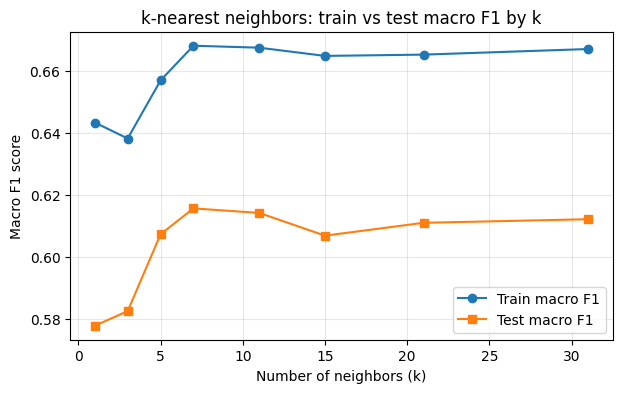

Figure description: A line chart with the number of neighbors k on the horizontal axis, from 1 to 31, and macro F1 on the vertical axis. Two lines are drawn, train and test. The train line starts at 0.643 at k=1 and rises to 0.667 at k=31. The test line peaks at 0.616 at k=7 and ends at 0.612 at k=31. The gap between the lines is widest at k=1 (0.066) and narrowest at k=5 (0.050). Values by k: k=1: train 0.643, test 0.578; k=3: train 0.638, test 0.583; k=5: train 0.657, test 0.607; k=7: train 0.668, test 0.616; k=11: train 0.668, test 0.614; k=15: train 0.665, test 0.607; k=21: train 0.665, test 0.611; k=31: train 0.667, test 0.612.


In [11]:
from sklearn.metrics import f1_score
from sklearn.model_selection import GridSearchCV

# The search tunes KNN on the selected features
k_values = [1, 3, 5, 7, 11, 15, 21, 31]
param_grid = {
    "n_neighbors": k_values,
    "weights": ["uniform", "distance"],
    "p": [1, 2],
}

grid = GridSearchCV(
    KNeighborsClassifier(),
    param_grid,
    scoring="f1_macro",
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=29),
    n_jobs=-1,
)
grid.fit(X_train_selected, y_train)

print(f"Combinations searched: {len(grid.cv_results_['params'])}")
print("\nBest under macro F1")
print("  parameters:", grid.best_params_)
print(f"  cross-validated macro F1: {grid.best_score_:.4f}")

y_pred = grid.predict(X_test_selected)
print(f"\nTest macro F1 for the best model: {f1_score(y_test, y_pred, average='macro'):.4f}")

# Sweep over n_neighbors, holding every other best parameter fixed
best_params = grid.best_params_
print(f"\nSweep of n_neighbors (other settings: "
      f"{ {k: v for k, v in best_params.items() if k != 'n_neighbors'} }), scored with macro F1")

train_scores, test_scores = [], []
print(f"{'k':>4} {'train':>8} {'test':>8} {'gap':>8}")
for k in k_values:
    model = KNeighborsClassifier(**{**best_params, "n_neighbors": k})
    model.fit(X_train_selected, y_train)
    tr = f1_score(y_train, model.predict(X_train_selected), average="macro")
    te = f1_score(y_test, model.predict(X_test_selected), average="macro")
    train_scores.append(tr)
    test_scores.append(te)
    print(f"{k:>4} {tr:>8.4f} {te:>8.4f} {tr - te:>8.4f}")

# Plot
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(k_values, train_scores, marker="o", label="Train macro F1")
ax.plot(k_values, test_scores, marker="s", label="Test macro F1")
ax.set_xlabel("Number of neighbors (k)")
ax.set_ylabel("Macro F1 score")
ax.set_title("k-nearest neighbors: train vs test macro F1 by k")
ax.legend()
ax.grid(True, alpha=0.3)
plt.show()

# Text description of the plot, built from the numbers above and passed to the helper
gaps = np.array(train_scores) - np.array(test_scores)
i_best = int(np.argmax(test_scores))
i_gap = int(np.argmax(gaps))
trend = "falls" if train_scores[-1] < train_scores[0] else "rises"
values = "; ".join(f"k={k}: train {tr:.3f}, test {te:.3f}"
                   for k, tr, te in zip(k_values, train_scores, test_scores))
description = (
    f"A line chart with the number of neighbors k on the horizontal axis, from {k_values[0]} to "
    f"{k_values[-1]}, and macro F1 on the vertical axis. Two lines are drawn, train and test. "
    f"The train line starts at {train_scores[0]:.3f} at k={k_values[0]} and {trend} to "
    f"{train_scores[-1]:.3f} at k={k_values[-1]}. "
    f"The test line peaks at {test_scores[i_best]:.3f} at k={k_values[i_best]} and ends at "
    f"{test_scores[-1]:.3f} at k={k_values[-1]}. "
    f"The gap between the lines is widest at k={k_values[i_gap]} ({gaps[i_gap]:.3f}) and "
    f"narrowest at k={k_values[int(np.argmin(gaps))]} ({gaps.min():.3f}). "
    f"Values by k: {values}."
)
describe_figure(description)

### Recommendation

I recommend k-nearest neighbors. On the same stratified split it scored 0.9177 test accuracy against a majority-class baseline of 0.8652 (+0.0525). Its 5-fold cross-validation mean was 0.9184 with a standard deviation of 0.0022, and its train-test gap was only 0.0061, so it is stable and not overfit. After tuning, the best settings were k=11, p=1, and distance weighting, with a cross-validated macro F1 of 0.6233 and a test macro F1 of 0.6143. The train-test gap in macro F1 at each k stayed between about 0.05 and 0.07.

I reject logistic regression. Its test accuracy was 0.5055, which is 0.3597 below the baseline, and its cross-validation mean was 0.5078. The random forest (0.7657 test accuracy) was also below the baseline.

I cannot yet tell whether this result will hold up. The tuned KNN beats the baseline by only about six points (0.9243 test accuracy against 0.8652), accuracy is dominated by Gasoline (86.5 percent of rows), and the evaluation below shows it does not do well on the small classes. The scaler and feature selection were fit on the whole training split before cross-validation, so the cross-validation numbers are slightly optimistic. The random split also puts near-identical vehicle configurations in both train and test, which may inflate the accuracy of a nearest-neighbor model.

## 6. Evaluation of the recommended model

The tuned KNN is evaluated on the held-out test split with a labeled confusion table (rows are the true class, columns the predicted class), plus per-class precision, recall, and F1 beside macro F1.

In [12]:
from sklearn.metrics import f1_score, recall_score, precision_score

# The recommended model: KNN with the settings chosen by the macro-F1 grid search
best_knn = grid.best_estimator_
y_pred = best_knn.predict(X_test_selected)
class_names = list(class_le.classes_)

print("Confusion table (rows are the true class, columns are the predicted class)")
cm_table = confusion_table(y_test, y_pred, class_names)

# Metric beyond accuracy: macro F1, with per-class precision, recall and F1 beside it
print()
print(f"Test accuracy:  {best_knn.score(X_test_selected, y_test):.4f}")
print(f"Test macro F1:  {f1_score(y_test, y_pred, average='macro'):.4f}")
print(f"Majority-class baseline accuracy: {np.bincount(y_test).max() / len(y_test):.4f}")

print()
print(f"{'class':<10} {'precision':>10} {'recall':>8} {'F1':>8} {'rows':>7}")
prec = precision_score(y_test, y_pred, average=None, zero_division=0)
rec = recall_score(y_test, y_pred, average=None, zero_division=0)
f1s = f1_score(y_test, y_pred, average=None, zero_division=0)
for idx, name in enumerate(class_names):
    print(f"{name:<10} {prec[idx]:>10.4f} {rec[idx]:>8.4f} {f1s[idx]:>8.4f} {int((y_test == idx).sum()):>7d}")

# Text reading of the confusion table: the largest off-diagonal cells
print()
print("Largest confusions (true class -> predicted class: count):")
off = cm_table.values.copy()
np.fill_diagonal(off, 0)
for flat in np.argsort(off, axis=None)[::-1][:5]:
    r, c = np.unravel_index(flat, off.shape)
    if off[r, c] > 0:
        print(f"  {class_names[r]} -> {class_names[c]}: {off[r, c]}")

Confusion table (rows are the true class, columns are the predicted class)
                pred Diesel  pred EV  pred Flex fuel  pred Gasoline  pred Hybrid  pred Plug-in
true Diesel             178        0               3            155            8             0
true EV                   0      473               0              0            0             0
true Flex fuel            0        0             141            315            4             1
true Gasoline            13        0              86          12485           96             7
true Hybrid               0        0               3            277          268            19
true Plug-in              0        0               0             85           38             9

Test accuracy:  0.9243
Test macro F1:  0.6143
Majority-class baseline accuracy: 0.8652

class       precision   recall       F1    rows
Diesel         0.9319   0.5174   0.6654     344
EV             1.0000   1.0000   1.0000     473
Flex fuel      0.6052   0.3

### Why macro F1, and will it hold up?

I chose macro F1, which averages the F1 score of each class equally, and I read it beside the per-class precision and recall and the counts in the confusion table. Accuracy is a poor fit for this question because a model that always predicts Gasoline scores 0.8652, and the question is whether each of the six fuel types can be identified. Plug-in is 0.9 percent of the rows, so it barely moves accuracy but counts as much as Gasoline in macro F1. F1 also balances precision and recall, so a class cannot score well by being over-predicted or ignored.

The tuned KNN (k=11, p=1, distance weighting) has a test accuracy of 0.9243, which is 0.0591 above the baseline, but a test macro F1 of only 0.6143. The gap between those two numbers comes from the small classes. Gasoline is almost always right (recall 0.9841, 12,485 of 12,687 rows), and EV is perfect (precision and recall 1.0000, all 473 rows). The others are missed often. Diesel recall is 0.5174 (178 of 344), Hybrid is 0.4727 (268 of 567), Flex fuel is 0.3059 (141 of 461), and Plug-in is 0.0682 (9 of 132). When the model is wrong it almost always says Gasoline: 315 Flex fuel rows, 277 Hybrid rows, 155 Diesel rows, and 85 Plug-in rows were predicted as Gasoline. Plug-in rows that were not called Gasoline were mostly called Hybrid (38 of 132), and its precision is 0.2500. The accuracy figure is mostly a statement about Gasoline.

**Will it hold up?** The evidence points in different directions. The cross-validation spread is small: the default KNN's five fold accuracies have a standard deviation of 0.0022 around a mean of 0.9184. The train-test gap is small too, 0.0061, so it is not memorizing the training rows. But both of those are accuracy measures, and accuracy is dominated by Gasoline, so they show the model is stable, not that it is useful for the small classes. For those, the recall figures above are the evidence, and they say it would miss most Flex fuel, Hybrid, and Plug-in vehicles. The perfect EV result is probably not general skill either: I set `displ` and `cylinders` to 0 for EV rows, so those two features give EVs away, which is the kind of stand-in described in the feature discussion above. The limitations section adds a further reason for caution: every row is a laboratory test of a vehicle certified for U.S. sale, and year, brand, and body style are tangled up with the classes, so I would not expect the model to hold for vehicles outside the catalog, for brands with little history in it, or for fuel types it never saw.

**Conclusion:** this model can tell EVs and Gasoline vehicles apart on these features, and it cannot yet be trusted to identify Flex fuel, Hybrid, Diesel, or Plug-in vehicles.

## 7. Summary and next steps

### Summary

**Data collection.** I downloaded `vehicles.csv.zip` from fueleconomy.gov into pandas (50,407 rows and 84 columns). I built the label from `atvType`: blank became Gasoline, and five rare fuel types (122 rows) were dropped, leaving six classes.

**Preprocessing.** I turned blank flags into 0/1, filled `startStop` with "unknown", set EV engine size and cylinders to 0, and dropped six mostly empty columns and 1,319 rows with other gaps. I one-hot encoded five nominal columns, removed 209 rows whose categories had fewer than 10 rows, made a 70/30 stratified split, scaled using the training split, and used a 500-tree random forest to cut 149 encoded columns to 7. The hardest decision was how to handle rare categories. Dropping their rows ended the unseen-category warning and removed the all-zeros rows, but it means the model never sees rare makes.

**Models.** I compared logistic regression, k-nearest neighbors, and a random forest against a majority-class baseline of 0.8652. Only KNN beat it, with 0.9177 test accuracy and a cross-validation mean of 0.9184. Logistic regression scored 0.5055 and the forest 0.7657, both below the baseline, though both used `class_weight="balanced"`. Tuning the KNN by macro F1 gave a test accuracy of 0.9243 and a test macro F1 of 0.6143.

**Did it answer the question?** Partly. A vehicle's fuel type can be predicted from seven specifications about six points better than always guessing Gasoline, but it does not work for the small classes. On the test split, recall was 0.0682 for Plug-in, 0.3059 for Flex fuel, 0.4727 for Hybrid, and 0.5174 for Diesel, and most of the misses were predicted as Gasoline. Only EV (1.0000) and Gasoline (0.9841) were identified reliably.

**Lessons.** Preprocessing has to be fit on the training split only, and a pipeline is the way to keep it that way. A pipeline step that selects columns by name needs a DataFrame, not an array, which is why my first grid search failed. Dropping the first one-hot category makes unseen categories ambiguous. Accuracy can look good when it only reflects the majority class.

### What didn't work, and what I would do next

In priority order:

1. **The small classes are still missed.** Accuracy is dominated by Gasoline (86.5 percent), and logistic regression and the forest fell below the baseline on accuracy. The tuned KNN has a test macro F1 of 0.6143 against an accuracy of 0.9243, with recall of 0.0682 for Plug-in, 0.3059 for Flex fuel, 0.4727 for Hybrid, and 0.5174 for Diesel. KNN has no `class_weight` option, and scoring the grid search by macro F1 only picked its settings, so nothing in the KNN rewards getting small classes right. Next, resample the training split only (oversample Plug-in, Flex fuel, Hybrid, and Diesel, or undersample Gasoline) and check whether Plug-in recall rises above 0.0682 without Gasoline precision falling much below 0.9375. Then run the same per-class report for the class-weighted logistic regression and forest.
2. **Cross-validation is slightly optimistic.** Putting a 500-tree forest inside every fold made the search too slow, so I fit the selection once on the training split. Next, cache the forest per fold or use a cheaper selector, such as L1 logistic regression, inside the pipeline, and measure how much the scores drop.
3. **A random split may flatter the model.** It can put near-identical configurations (same model, adjacent years) in both train and test, and I dropped 209 rows to avoid unseen categories. Next, split by model year or by make so the test set looks like new vehicles, and list which makes were dropped.